In [1]:
# Import libraries required for clustering and visualization
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
# Load the Digits dataset and check its size and labels
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of images:", len(X))
print("Number of features:", X.shape[1])
print("First 10 labels:", y[:10])

Dataset shape: (1797, 64)
Number of images: 1797
Number of features: 64
First 10 labels: [0 1 2 3 4 5 6 7 8 9]


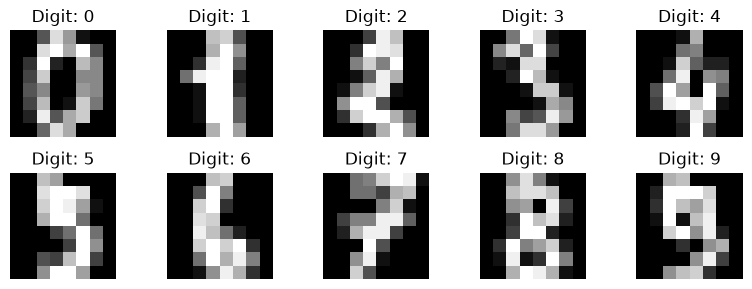

In [3]:
# Display the first 10 handwritten digit images
plt.figure(figsize=(8, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.images[i], cmap="gray")
    plt.title("Digit: " + str(y[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Scale the features to improve distance-based clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (1797, 64)
Scaled data shape: (1797, 64)


In [5]:
# Group the digit images into 10 clusters using K-Means
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("Number of clusters:", len(np.unique(clusters)))
print("First 10 cluster assignments:", clusters[:10])
print("Inertia:", round(kmeans.inertia_, 2))

Number of clusters: 10
First 10 cluster assignments: [2 0 0 8 4 8 5 7 8 8]
Inertia: 69813.56


In [6]:
# Evaluate cluster quality using silhouette score and inertia
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 3))
print("Inertia:", round(kmeans.inertia_, 2))

Silhouette Score: 0.139
Inertia: 69813.56


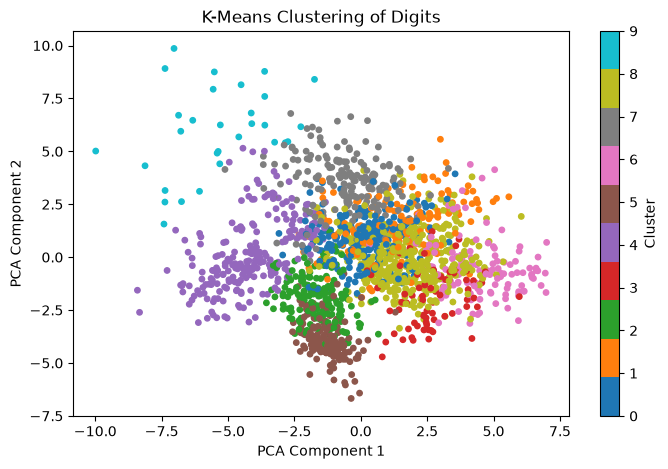

In [7]:
# Reduce the features to 2 dimensions and plot the clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=clusters, cmap="tab10", s=15)
plt.title("K-Means Clustering of Digits")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [8]:
# Compare the actual digit labels with assigned cluster numbers
for i in range(10):
    print("Actual digit:", y[i], "Cluster:", clusters[i])

Actual digit: 0 Cluster: 2
Actual digit: 1 Cluster: 0
Actual digit: 2 Cluster: 0
Actual digit: 3 Cluster: 8
Actual digit: 4 Cluster: 4
Actual digit: 5 Cluster: 8
Actual digit: 6 Cluster: 5
Actual digit: 7 Cluster: 7
Actual digit: 8 Cluster: 8
Actual digit: 9 Cluster: 8
